# DSCI 552 HW3

Justin Li

zyli@usc.edu

34004214

In [1]:
import itertools
import os
import re
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import f_classif

warnings.filterwarnings("ignore")
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
sns.set_style("whitegrid")
np.random.seed(42)

## 1(a) The AReM data

In [2]:
ROOT = "../data/AReM"
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
SERIES = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]


def read_instance(path):
    rows = []
    with open(path, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            parts = [p for p in re.split(r"[,\s]+", line) if p != ""]
            if len(parts) >= 7:
                rows.append([float(x) for x in parts[:7]])
    return pd.DataFrame(rows, columns=["time"] + SERIES)


def list_files(activity):
    files = [f for f in os.listdir(os.path.join(ROOT, activity)) if f.endswith(".csv")]
    return sorted(files, key=lambda f: int(re.search(r"\d+", f).group()))


instances = []
for act in ACTIVITIES:
    for f in list_files(act):
        num = int(re.search(r"\d+", f).group())
        instances.append({"activity": act, "dataset": num,
                          "data": read_instance(os.path.join(ROOT, act, f))})

print("activities:", len(ACTIVITIES))
print("instances:", len(instances))
print("time series per instance:", len(SERIES))
print()
print(pd.Series([i["activity"] for i in instances]).value_counts()[ACTIVITIES].to_string())

activities: 7
instances: 88
time series per instance: 6

bending1     7
bending2     6
cycling     15
lying       15
sitting     15
standing    15
walking     15


In [3]:
lengths = pd.Series({f"{i['activity']}/dataset{i['dataset']}.csv": len(i["data"])
                     for i in instances})
print("rows per instance:")
print(lengths.value_counts().to_string())
print()
print("instances not equal to 480 rows:")
print(lengths[lengths != 480].to_string())

rows per instance:
480    87
479     1

instances not equal to 480 rows:
sitting/dataset8.csv    479


In [4]:
instances[0]["data"].head()

,time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23
0,0.0,39.25,0.43,22.75,0.43,33.75,1.3
1,250.0,39.25,0.43,23.00,0.00,33.00,0.0
2,500.0,39.25,0.43,23.25,0.43,33.00,0.0
3,750.0,39.50,0.50,23.00,0.71,33.00,0.0
4,1000.0,39.50,0.50,24.00,0.00,33.00,0.0


The dataset has 7 folders, one per activity: bending1, bending2, cycling, lying, sitting, standing, and walking. Together they hold 88 instances, each instance being one person performing one activity for 120 seconds.

Each CSV file is one instance. A row in that file is a single reading from the wireless sensor network, taken every 250 ms at 20 Hz, so 480 rows cover the 120-second recording. A column is one of the 6 time series: avg_rss12, var_rss12, avg_rss13, var_rss13, avg_rss23, and var_rss23, which are the mean and variance of the received signal strength between each of the three sensor pairs, plus a time column holding the timestamp in milliseconds.

The instance counts per folder are 7 for bending1, 6 for bending2, and 15 each for cycling, lying, sitting, standing, and walking, giving 88 in total.

Four files needed minor cleaning, which the loader above handles. bending2/dataset4.csv is space-separated with Windows line endings instead of comma-separated, cycling/dataset9.csv and cycling/dataset14.csv carry a trailing comma on the final row that creates an empty eighth field, and sitting/dataset8.csv is missing the sample at t = 13500 ms, so it has 479 rows instead of 480. Splitting each line on either commas or whitespace and keeping the first 7 fields covers the first three cases. The missing row in sitting/dataset8.csv is left as is, since summary statistics over 479 of 480 samples are unaffected at this precision.

## 1(b) Train and test split

In [5]:
TEST_SETS = {"bending1": [1, 2], "bending2": [1, 2], "cycling": [1, 2, 3],
             "lying": [1, 2, 3], "sitting": [1, 2, 3], "standing": [1, 2, 3],
             "walking": [1, 2, 3]}

for inst in instances:
    inst["split"] = "test" if inst["dataset"] in TEST_SETS[inst["activity"]] else "train"
    inst["binary"] = "bending" if inst["activity"].startswith("bending") else "other"

split_counts = pd.DataFrame([{"activity": i["activity"], "split": i["split"]}
                             for i in instances])
table_b = split_counts.groupby(["activity", "split"]).size().unstack(fill_value=0)
table_b = table_b.loc[ACTIVITIES, ["train", "test"]]
table_b.loc["total"] = table_b.sum()
table_b

split,train,test
activity,,
bending1,5,2
bending2,4,2
cycling,12,3
lying,12,3
sitting,12,3
standing,12,3
walking,12,3
total,69,19


Datasets 1 and 2 in bending1 and bending2, and datasets 1, 2, and 3 in the other five folders, are held out as test data. Everything else is training data.

That gives 19 test instances and 69 training instances, out of 88. The split is applied by file number rather than at random, so it is reproducible and keeps every activity represented on both sides.

## 1(c)i Time-domain features used in time series classification

Time-domain features are computed directly from the raw signal values, with no transform to the frequency domain first. The ones in common use for time series classification are:

Location: minimum, maximum, mean, median, mode, and the trimmed mean.

Spread: standard deviation, variance, range (maximum minus minimum), interquartile range, mean absolute deviation, and root mean square.

Quantiles: first quartile, third quartile, and other percentiles.

Shape: skewness and kurtosis.

Energy and activity: signal energy, signal magnitude area, zero-crossing rate, and mean-crossing rate.

Temporal structure: autocorrelation at various lags, slope of a fitted trend line, first-difference statistics, and counts of peaks or local extrema.

Entropy and complexity: sample entropy, approximate entropy, and permutation entropy.

The assignment asks for seven of these, which the next part extracts: minimum, maximum, mean, median, standard deviation, first quartile, and third quartile.

## 1(c)ii Feature extraction

In [6]:
FEATURES = ["min", "max", "mean", "median", "std", "1stquart", "3rdquart"]


def extract(df):
    row = {}
    for i, s in enumerate(SERIES, start=1):
        v = df[s].values
        row[f"min{i}"] = v.min()
        row[f"max{i}"] = v.max()
        row[f"mean{i}"] = v.mean()
        row[f"median{i}"] = np.median(v)
        row[f"std{i}"] = v.std(ddof=1)
        row[f"1stquart{i}"] = np.percentile(v, 25)
        row[f"3rdquart{i}"] = np.percentile(v, 75)
    return row


X = pd.DataFrame([extract(i["data"]) for i in instances])
labels = pd.DataFrame([{"activity": i["activity"], "dataset": i["dataset"],
                        "split": i["split"], "binary": i["binary"]} for i in instances])
full = pd.concat([labels, X], axis=1)
full.index = pd.RangeIndex(1, len(full) + 1, name="Instance")
X.index = full.index

print("feature table shape:", full.shape, " feature columns:", X.shape[1])
full.head()

feature table shape: (88, 46)  feature columns: 42


,activity,dataset,split,binary,min1,max1,mean1,median1,std1,1stquart1,3rdquart1,min2,max2,mean2,median2,std2,1stquart2,3rdquart2,min3,max3,mean3,median3,std3,1stquart3,3rdquart3,min4,max4,mean4,median4,std4,1stquart4,3rdquart4,min5,max5,mean5,median5,std5,1stquart5,3rdquart5,min6,max6,mean6,median6,std6,1stquart6,3rdquart6
Instance,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
1,bending1,1,test,bending,37.25,45.00,40.6248,40.50,1.4770,39.25,42.00,0.0,1.30,0.3586,0.43,0.3226,0.00,0.50,4.0,29.50,19.0409,19.250,4.4630,16.00,23.2500,0.0,7.23,0.8325,0.50,0.9657,0.00,1.120,27.25,38.25,34.3113,35.0,2.1884,33.0000,36.00,0.0,1.92,0.5706,0.43,0.5829,0.0,1.30
2,bending1,2,test,bending,38.00,45.67,42.8128,42.50,1.4355,42.00,43.67,0.0,1.22,0.3724,0.47,0.2892,0.00,0.50,2.0,29.50,20.0970,21.000,3.8937,19.00,22.2500,0.0,5.76,0.8764,0.50,1.0473,0.00,1.145,27.67,38.50,33.0246,33.0,1.9953,32.0000,34.50,0.0,3.11,0.5711,0.43,0.6010,0.0,1.30
3,bending1,3,train,bending,35.00,47.40,43.9545,44.33,1.5588,43.00,45.00,0.0,1.70,0.4263,0.47,0.3387,0.00,0.50,6.5,29.75,22.1224,23.000,3.0309,19.75,24.0000,0.0,4.44,0.4973,0.43,0.5507,0.00,0.830,29.00,38.50,35.5885,36.0,1.9996,35.3625,36.50,0.0,1.79,0.4933,0.43,0.5135,0.0,0.94
4,bending1,4,train,bending,33.00,47.75,42.1798,43.50,3.6707,39.15,45.00,0.0,3.00,0.6960,0.50,0.6309,0.00,1.12,8.5,30.00,22.1836,23.000,3.8105,20.50,24.3725,0.0,5.15,0.9899,0.83,0.9537,0.43,1.300,20.00,38.67,33.4939,35.0,3.8494,30.4575,36.33,0.0,2.18,0.6135,0.50,0.5243,0.0,1.00
5,bending1,5,train,bending,33.00,45.75,41.6781,41.75,2.2435,41.33,42.75,0.0,2.83,0.5360,0.50,0.4055,0.43,0.71,3.0,28.25,19.0066,19.125,4.0871,16.50,22.0625,0.0,6.42,0.8419,0.50,0.9288,0.43,1.120,23.67,37.50,29.8571,30.0,2.4110,28.4575,31.25,0.0,1.79,0.3833,0.43,0.3892,0.0,0.50


In [7]:
full.iloc[:, :11]

,activity,dataset,split,binary,min1,max1,mean1,median1,std1,1stquart1,3rdquart1
Instance,,,,,,,,,,,
1,bending1,1,test,bending,37.25,45.00,40.6248,40.500,1.4770,39.2500,42.0000
2,bending1,2,test,bending,38.00,45.67,42.8128,42.500,1.4355,42.0000,43.6700
3,bending1,3,train,bending,35.00,47.40,43.9545,44.330,1.5588,43.0000,45.0000
4,bending1,4,train,bending,33.00,47.75,42.1798,43.500,3.6707,39.1500,45.0000
5,bending1,5,train,bending,33.00,45.75,41.6781,41.750,2.2435,41.3300,42.7500
6,bending1,6,train,bending,37.00,48.00,43.4550,43.250,1.3861,42.5000,45.0000
7,bending1,7,train,bending,36.25,48.00,43.9691,44.500,1.6184,43.3100,44.6700
8,bending2,1,test,bending,12.75,51.00,24.5630,24.250,3.7375,23.1875,26.5000
9,bending2,2,test,bending,0.00,42.75,27.4646,28.000,3.5836,25.5000,30.0000


Seven features for each of the 6 time series gives 42 feature columns, and with 88 instances the new dataset is an 88 by 42 table. The four label columns carried alongside it are the activity, the dataset number, the train or test split from 1(b), and the binary bending versus other label.

Column names follow the numbering in the assignment, so min1 through 3rdquart1 belong to time series 1 (avg_rss12), and the subscript 6 columns belong to time series 6 (var_rss23). Features are used directly without normalization.

## 1(c)iii Standard deviation of each feature and bootstrap confidence intervals

In [8]:
def bootstrap_std_ci(values, n_boot=10000, alpha=0.10, seed=42):
    rng = np.random.default_rng(seed)
    n = len(values)
    draws = values[rng.integers(0, n, size=(n_boot, n))]
    stats = draws.std(ddof=1, axis=1)
    lo, hi = np.percentile(stats, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return lo, hi


rows = []
for c in X.columns:
    v = X[c].values
    lo, hi = bootstrap_std_ci(v)
    rows.append({"feature": c, "std": v.std(ddof=1), "ci_lower": lo, "ci_upper": hi,
                 "ci_width": hi - lo})

ci = pd.DataFrame(rows).set_index("feature")
ci.round(4)

,std,ci_lower,ci_upper,ci_width
feature,,,,
min1,9.5700,8.2360,10.7739,2.5379
max1,4.3944,3.3399,5.2931,1.9532
mean1,5.3357,4.7038,5.8758,1.1720
median1,5.4401,4.7840,6.0063,1.2223
std1,1.7722,1.5694,1.9495,0.3801
1stquart1,6.1536,5.5738,6.6486,1.0748
3rdquart1,5.1389,4.3386,5.8340,1.4954
min2,0.0000,0.0000,0.0000,0.0000
max2,5.0627,4.6306,5.4011,0.7705


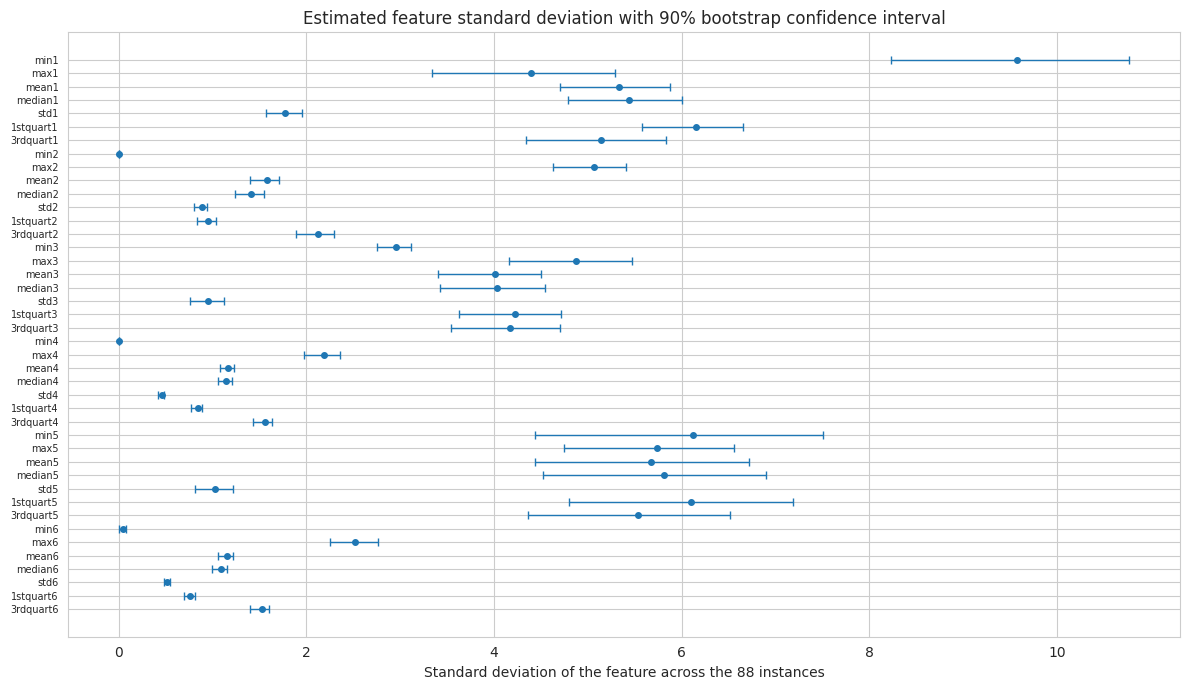

In [9]:
ordered = [f"{t}{i}" for i in range(1, 7) for t in FEATURES]
plt.figure(figsize=(12, 7))
y = np.arange(len(ordered))
sub = ci.loc[ordered]
plt.errorbar(sub["std"], y,
             xerr=[sub["std"] - sub["ci_lower"], sub["ci_upper"] - sub["std"]],
             fmt="o", ms=4, capsize=3, lw=1)
plt.yticks(y, ordered, fontsize=7)
plt.gca().invert_yaxis()
plt.xlabel("Standard deviation of the feature across the 88 instances")
plt.title("Estimated feature standard deviation with 90% bootstrap confidence interval")
plt.tight_layout()
plt.show()

In [10]:
print("widest intervals:")
print(ci.nlargest(5, "ci_width").round(4).to_string())
print()
print("degenerate features (zero variability across all 88 instances):")
print(ci[ci["std"] == 0].round(4).to_string())

widest intervals:
              std  ci_lower  ci_upper  ci_width
feature                                        
min5       6.1240    4.4382    7.5047    3.0665
min1       9.5700    8.2360   10.7739    2.5379
1stquart5  6.0965    4.8020    7.1879    2.3859
median5    5.8138    4.5219    6.8992    2.3773
mean5      5.6756    4.4358    6.7176    2.2817

degenerate features (zero variability across all 88 instances):
         std  ci_lower  ci_upper  ci_width
feature                                   
min2     0.0       0.0       0.0       0.0
min4     0.0       0.0       0.0       0.0


The standard deviations are estimated across the 88 instances, one value per feature, and the 90% confidence intervals come from the percentile method on 10000 bootstrap resamples with replacement.

Spread varies widely between features. min1 has a standard deviation of 9.57 with an interval of 8.24 to 10.77, and min5 is the most uncertain at 6.12 with an interval of 4.44 to 7.50, a width of 3.07. The variance series are much tighter: std4 has a standard deviation of 0.46 with an interval of 0.42 to 0.49.

Two features are degenerate. min2 and min4 are exactly 0 in all 88 instances, so their standard deviation is 0 and the bootstrap interval collapses to a point. These are the minima of var_rss12 and var_rss13, and over 480 samples every recording contains at least one moment where the signal variance reads zero. Both carry no information and should be dropped before any model is fitted.

In general the intervals for features built on the avg_rss series are wider than those for the var_rss series, which reflects the larger raw scale of the average signal strength rather than any difference in reliability.

## 1(c)iv The three most important features

In [11]:
train_mask = full["split"] == "train"
X_train = X[train_mask]
live = [c for c in X.columns if X_train[c].nunique() > 1]

F_multi = pd.Series(f_classif(X_train[live], full.loc[train_mask, "activity"])[0], index=live)
F_binary = pd.Series(f_classif(X_train[live], full.loc[train_mask, "binary"])[0], index=live)

rows = []
for t in FEATURES:
    cols = [c for c in (f"{t}{i}" for i in range(1, 7)) if c in live]
    rows.append({"feature_type": t, "usable_series": len(cols),
                 "mean_F_7class": F_multi[cols].mean(), "max_F_7class": F_multi[cols].max(),
                 "mean_F_bending": F_binary[cols].mean(), "max_F_bending": F_binary[cols].max()})

importance = pd.DataFrame(rows).set_index("feature_type").sort_values(
    "mean_F_7class", ascending=False)
importance.round(2)

,usable_series,mean_F_7class,max_F_7class,mean_F_bending,max_F_bending
feature_type,,,,,
mean,6,368.17,900.16,10.57,43.88
3rdquart,6,350.44,807.05,10.31,40.12
median,6,317.75,800.79,9.44,36.14
1stquart,6,154.11,346.34,9.25,34.43
std,6,109.17,360.89,3.45,9.05
max,6,30.03,47.73,18.13,91.99
min,4,14.64,24.10,8.59,34.19


In [12]:
redundancy = pd.DataFrame(index=FEATURES, columns=FEATURES, dtype=float)
for a, b in itertools.product(FEATURES, FEATURES):
    vals = [abs(np.corrcoef(X[f"{a}{i}"], X[f"{b}{i}"])[0, 1])
            for i in range(1, 7)
            if f"{a}{i}" in live and f"{b}{i}" in live]
    redundancy.loc[a, b] = np.mean(vals) if vals else np.nan

redundancy.round(3)

,min,max,mean,median,std,1stquart,3rdquart
min,1.000,0.371,0.598,0.569,0.397,0.603,0.535
max,0.371,1.000,0.791,0.762,0.600,0.729,0.813
mean,0.598,0.791,1.000,0.992,0.625,0.981,0.985
median,0.569,0.762,0.992,1.000,0.626,0.980,0.973
std,0.397,0.600,0.625,0.626,1.000,0.629,0.594
1stquart,0.603,0.729,0.981,0.980,0.629,1.000,0.946
3rdquart,0.535,0.813,0.985,0.973,0.594,0.946,1.000


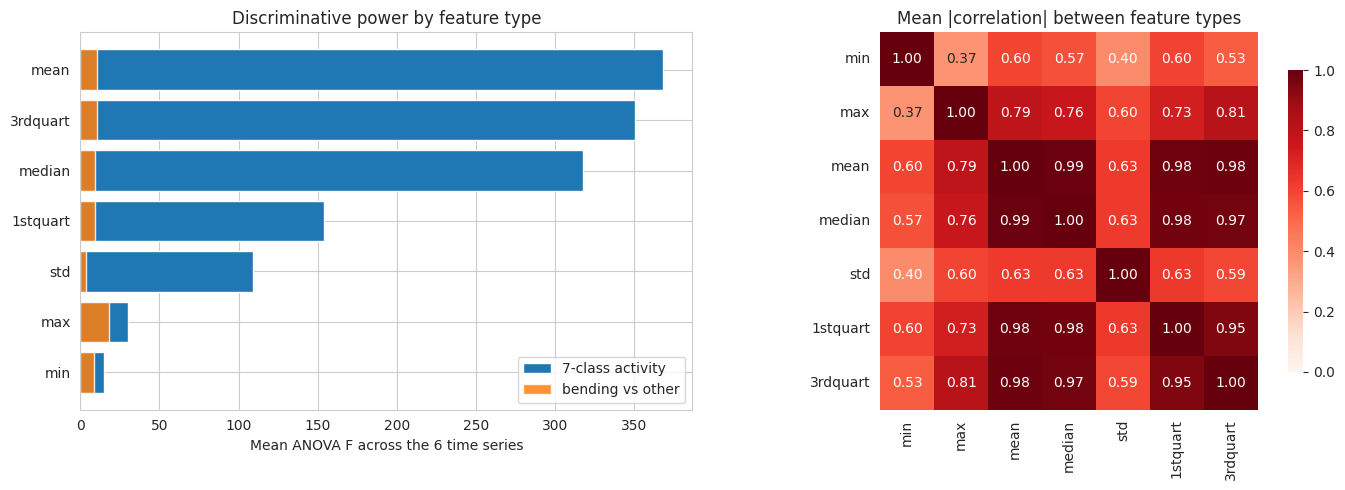

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

imp_sorted = importance.sort_values("mean_F_7class")
axes[0].barh(imp_sorted.index, imp_sorted["mean_F_7class"], color="tab:blue",
             label="7-class activity")
axes[0].barh(imp_sorted.index, imp_sorted["mean_F_bending"], color="tab:orange",
             alpha=0.85, label="bending vs other")
axes[0].set_xlabel("Mean ANOVA F across the 6 time series")
axes[0].set_title("Discriminative power by feature type")
axes[0].legend()

sns.heatmap(redundancy.astype(float), annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1,
            square=True, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title("Mean |correlation| between feature types")
plt.tight_layout()
plt.show()

In [14]:
chosen = ["mean", "max", "std"]
pairs = redundancy.loc[chosen, chosen].values[np.triu_indices(3, k=1)]
print("selected features:", chosen)
print(f"mean pairwise |r| within the selection: {pairs.mean():.3f}")
print()
print("for comparison, the three location-like types:")
alt = ["mean", "median", "3rdquart"]
alt_pairs = redundancy.loc[alt, alt].values[np.triu_indices(3, k=1)]
print(f"   {alt} mean pairwise |r| = {alt_pairs.mean():.3f}")

selected features: ['mean', 'max', 'std']
mean pairwise |r| within the selection: 0.672

for comparison, the three location-like types:
   ['mean', 'median', '3rdquart'] mean pairwise |r| = 0.983


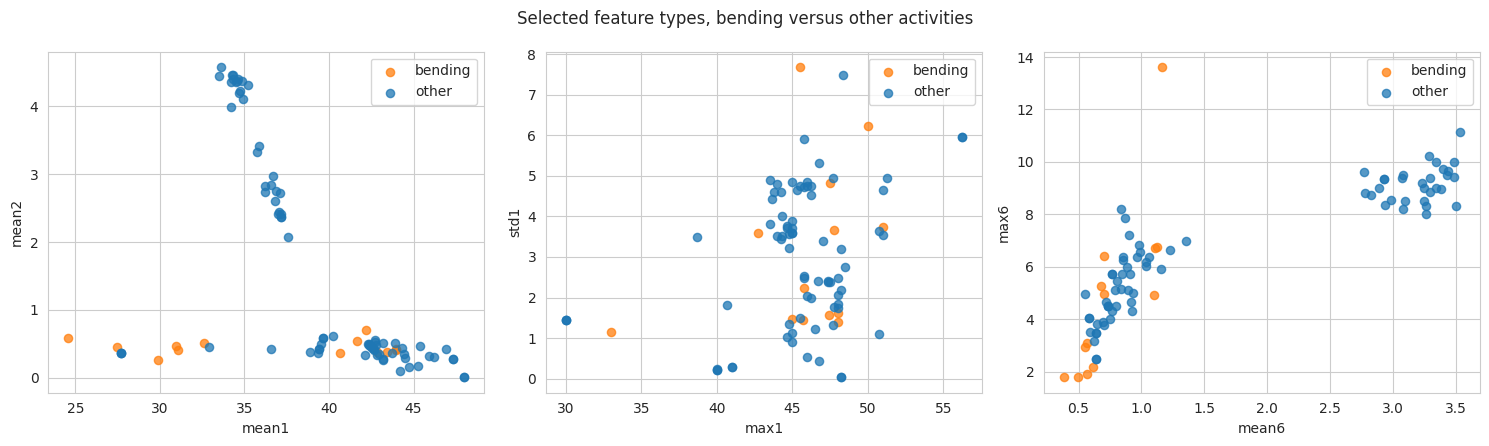

In [15]:
scatter_cols = [("mean1", "mean2"), ("max1", "std1"), ("mean6", "max6")]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (a, b) in zip(axes, scatter_cols):
    for grp, color in [("bending", "tab:orange"), ("other", "tab:blue")]:
        m = full["binary"] == grp
        ax.scatter(full.loc[m, a], full.loc[m, b], s=35, alpha=0.75, label=grp, color=color)
    ax.set_xlabel(a)
    ax.set_ylabel(b)
    ax.legend()
fig.suptitle("Selected feature types, bending versus other activities")
plt.tight_layout()
plt.show()

I selected mean, maximum, and standard deviation.

The ranking by ANOVA F on the training set puts mean first for separating the seven activities, with an average F of 368.2 across the six time series and a peak of 900.2 on mean2. Third quartile (350.4) and median (317.8) follow closely, but the correlation table shows why they add nothing: mean, median, first quartile, and third quartile all correlate above 0.94 with each other, averaging 0.99 for mean against median. They are four measurements of the same thing. Choosing all three location statistics gives a mean pairwise correlation of 0.983, against 0.672 for the selection above.

Maximum earns its place on the binary problem rather than the seven-class one. It is the strongest single type for separating bending from the other activities, with an average F of 18.1 and 92.0 on max5, roughly double the next best. It also correlates only 0.791 with mean, so it carries information the mean does not.

Standard deviation is the least redundant of all the types, correlating 0.625 with mean and 0.600 with max, and it is the only selected feature that measures dispersion rather than level. Its seven-class F of 109.2 is well behind the location family but far ahead of minimum.

Minimum is the weakest choice despite being suggested as an option. Two of its six columns, min2 and min4, are constant at zero and carry no information at all, and of the remaining four only min5 is useful, with a binary F of 34.2. Its average seven-class F of 14.6 is the lowest of any type.

The scatter plots show the practical effect: bending instances separate cleanly from the other activities on the mean and maximum of the variance series, which is what the next assignment will use.

## 2. ISLR 3.7.4

A linear model and a cubic model are fitted to 100 observations with one predictor. The cubic model contains the linear model as a special case, with the quadratic and cubic coefficients set to zero, so the two are nested. That nesting drives the answers to (a) and (c).

(a) True relationship is linear, training RSS: The cubic regression will have lower training RSS. Least squares chooses coefficients to minimize RSS over a larger parameter space for the cubic model, and the linear fit is always available to it by setting the extra coefficients to zero. So the cubic training RSS can never exceed the linear training RSS, and with real data it will be strictly lower, since the extra terms will pick up some noise. This holds regardless of what the true relationship is.

(b) True relationship is linear, test RSS: The linear regression will have lower test RSS. The linear model is correctly specified here, so it is unbiased, and it estimates only two parameters. The cubic model is also unbiased, because the true quadratic and cubic coefficients are zero and least squares estimates them near zero, but estimating two extra parameters adds variance without removing any bias. That extra variance shows up directly as higher expected test error, so the cubic model overfits.

(c) True relationship is not linear, training RSS: The cubic regression will again have lower training RSS, and we have enough information to say so. The argument from (a) does not depend on the true relationship at all. Because the models are nested, the cubic fit minimizes RSS over a superset of the linear model's parameter space, so its training RSS is less than or equal to the linear model's for any dataset. Adding predictors can only reduce training RSS.

(d) True relationship is not linear, test RSS: There is not enough information to tell. The answer depends on how far the truth is from linear, which the question says we do not know. If the departure from linearity is mild, the bias the cubic model removes is small and the variance it adds from two extra parameters dominates, so the linear model wins. If the truth is strongly non-linear, and particularly if it is close to cubic, the bias reduction is large and outweighs the added variance, so the cubic model wins. Without knowing the size of the non-linearity relative to the noise level and the sample size, either outcome is possible.